# SCIKIT-LEARN MASTERY — NOTEBOOK 1
## Chapters 1–5: The Scikit-learn Ecosystem → The Estimator API → Data Representation → Train/Validation/Test Split → Preprocessing Ecosystem (Scaling)

**Prerequisite assumption:** You already know Python, NumPy, Pandas, Matplotlib/Seaborn, and Decision Tree/Random Forest theory at a working level. This course does not re-teach those — it builds professional ML engineering skill directly on top of them.

### SCIKIT-LEARN MASTERY PROGRESS
- [x] Scikit-learn Ecosystem
- [x] Estimator API
- [x] Data Representation
- [x] Train/Test Split
- [ ] Preprocessing *(this notebook covers Scaling; Encoding/Imputation/Feature Generation come in Notebook 2)*
- [ ] Everything else (94 more chapters ahead)

Run every cell in order — later notebooks build directly on objects created here.


---
# CHAPTER 1 — THE SCIKIT-LEARN ECOSYSTEM

## 1. Concept

```
Python
  ↓
NumPy        -- numerical arrays, linear algebra
  ↓
Pandas       -- labeled, structured data
  ↓
Matplotlib/Seaborn -- visualization
  ↓
Scikit-learn -- ML algorithms, preprocessing, model selection, evaluation
  ↓
Trained Model -- a fitted, reusable prediction function
```

Scikit-learn is a **general-purpose machine learning library** built on top of NumPy and SciPy. It is not a deep learning framework, not a data manipulation library, and not a visualization library — it is specifically the layer that turns *already-clean numerical arrays* into *fitted models*, and provides the surrounding tooling (preprocessing, cross-validation, metrics, pipelines) to do that reliably and reproducibly.

## 2. Why It Was Created / What Problem It Solves

Before Scikit-learn (2007, originally a Google Summer of Code project), doing ML in Python meant stitching together inconsistent, algorithm-specific APIs. Scikit-learn's core contribution isn't any single algorithm — it's a **uniform, predictable interface** (`fit`/`predict`/`transform`) that every algorithm, preprocessing step, and evaluation tool honors identically. This uniformity is *why* Pipelines, cross-validation, and hyperparameter search can all work generically across hundreds of different algorithms without special-casing each one.

## 3. The Broader Ecosystem — Division of Responsibility

| Library | Responsibility |
|---|---|
| **NumPy** | N-dimensional arrays, vectorized math, linear algebra primitives |
| **SciPy** | Scientific computing built on NumPy (optimization, sparse matrices, statistics) — Scikit-learn uses SciPy's sparse matrix format and some of its optimizers internally |
| **Pandas** | Labeled, heterogeneous, 2D tabular data — the format you typically *prepare* data in before handing it to Scikit-learn |
| **Matplotlib / Seaborn** | Visualization — including model diagnostics (Scikit-learn even ships thin `*Display` wrapper classes, e.g. `ConfusionMatrixDisplay`, built on Matplotlib) |
| **Scikit-learn** | Preprocessing, feature engineering primitives, supervised/unsupervised algorithms, model selection, evaluation metrics, pipelines |
| **Joblib** | Scikit-learn's parallelization backend (`n_jobs`) and the standard tool for persisting fitted models to disk |

## 4. What Scikit-learn Does NOT Primarily Provide
- **Deep learning** — it has only a basic `MLPClassifier`/`MLPRegressor`; for anything beyond small feedforward networks, use PyTorch/TensorFlow.
- **Data cleaning/wrangling** — that's Pandas' job; Scikit-learn expects you to arrive with a numeric-or-categorical, roughly-tidy array/DataFrame.
- **Visualization** (beyond a handful of thin diagnostic wrappers) — that's Matplotlib/Seaborn's job.
- **Dedicated time-series forecasting** — `TimeSeriesSplit` supports *validating* time-ordered data, but there's no ARIMA/Prophet-style forecasting model built in.
- **Gradient-boosted-tree state-of-the-art performance at massive scale** — `HistGradientBoostingClassifier`/`Regressor` are genuinely competitive, but XGBoost/LightGBM/CatBoost remain the industry standard for large tabular competitions (covered comparatively in Chapter 87).

## 5. What Scikit-learn DOES Provide (the map ahead)
```
sklearn.preprocessing      -- scaling, encoding, imputation, feature generation
sklearn.compose            -- ColumnTransformer (apply different preprocessing per column)
sklearn.pipeline           -- Pipeline, FeatureUnion (chain steps safely)
sklearn.linear_model       -- LinearRegression, LogisticRegression, Ridge, Lasso, ...
sklearn.tree               -- DecisionTreeClassifier/Regressor
sklearn.ensemble           -- RandomForest, GradientBoosting, Voting, Stacking, ...
sklearn.svm                -- SVC, SVR
sklearn.neighbors          -- KNeighborsClassifier/Regressor
sklearn.naive_bayes        -- GaussianNB, MultinomialNB, ...
sklearn.cluster            -- KMeans, DBSCAN, AgglomerativeClustering, ...
sklearn.decomposition      -- PCA, NMF, ...
sklearn.model_selection    -- train_test_split, cross_val_score, GridSearchCV, ...
sklearn.metrics            -- accuracy_score, roc_auc_score, mean_squared_error, ...
sklearn.feature_selection  -- SelectKBest, RFE, ...
sklearn.inspection         -- permutation_importance, PartialDependenceDisplay
```


In [1]:
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt

print("scikit-learn version:", sklearn.__version__)
print("numpy version:", np.__version__)
print("pandas version:", pd.__version__)


scikit-learn version: 1.6.1
numpy version: 2.1.3
pandas version: 2.2.3


### Common Mistakes
- Treating Scikit-learn as if it should also clean/wrangle raw messy data — that's Pandas' job; arriving with an un-tidied DataFrame and expecting `model.fit()` to somehow handle it produces confusing errors, not graceful degradation.
- Assuming Scikit-learn's neural network support is comparable to PyTorch/TensorFlow — `MLPClassifier` exists but is not the tool for any serious deep learning work.

### Interview Insight
**Q: In one sentence, what does Scikit-learn provide that NumPy/Pandas don't?**
A: A uniform `fit`/`predict`/`transform` API spanning hundreds of ML algorithms and preprocessing steps, plus the surrounding infrastructure (pipelines, cross-validation, metrics, hyperparameter search) that makes composing and validating them reliable and reproducible — NumPy/Pandas give you arrays and tables, Scikit-learn gives you the modeling and evaluation layer built on top of them.

### Quiz (Chapter 1)
1. What is Scikit-learn's single most important architectural contribution, beyond any specific algorithm?
2. Name two things Scikit-learn deliberately does NOT provide, and which other library/tool fills that gap.
3. What role does Joblib play in the ecosystem?


---
# CHAPTER 2 — THE SCIKIT-LEARN API DESIGN

## 1. Concept — The Core Object Types

Every Scikit-learn object is one (or more) of these roles:

| Role | Core method(s) | Learns from data? | Example |
|---|---|---|---|
| **Estimator** | `.fit(X, y=None)` | Yes — the base role every other role builds on | Any model, scaler, or transformer |
| **Transformer** | `.fit(X)`, `.transform(X)`, `.fit_transform(X)` | Yes, learns *parameters* to transform data | `StandardScaler`, `OneHotEncoder` |
| **Predictor** | `.fit(X, y)`, `.predict(X)` | Yes, learns to predict a target | `LogisticRegression`, `RandomForestClassifier` |
| **Meta-estimator** | Wraps another estimator | Delegates to the wrapped estimator | `GridSearchCV`, `Pipeline`, `VotingClassifier` |

**"Estimator" is the umbrella term** — literally anything with a `.fit()` method is an estimator in Scikit-learn's vocabulary, including scalers and encoders (which "estimate" parameters like mean/std or category lists from the data) as well as models.

## 2. The Method Contract, Precisely

```python
estimator.fit(X, y)          # LEARNS from data; returns self (enables chaining); mutates the object in-place
transformer.transform(X)      # APPLIES a learned transformation; returns a new array; does NOT refit
transformer.fit_transform(X)  # fit(X) THEN transform(X) in one call -- often more efficient than two separate calls
predictor.predict(X)          # returns predicted labels/values using already-fitted parameters
predictor.predict_proba(X)    # (classifiers only) returns per-class probabilities
predictor.score(X, y)         # returns a default performance metric (accuracy for classifiers, R^2 for regressors)
estimator.get_params()        # returns the object's hyperparameters as a dict
estimator.set_params(**p)     # sets hyperparameters; returns self
```

## 3. Why This Consistency Matters — Concretely


In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

X_demo = np.array([[1.0, 200], [2.0, 300], [3.0, 100], [4.0, 400]])
y_demo = np.array([0, 1, 0, 1])

# Every one of these objects, despite being wildly different algorithms, honors the SAME .fit() signature:
for estimator in [StandardScaler(), LogisticRegression(), DecisionTreeClassifier(), SVC()]:
    if hasattr(estimator, "fit"):
        if estimator.__class__.__name__ == "StandardScaler":
            estimator.fit(X_demo)          # transformer: fit(X) only
        else:
            estimator.fit(X_demo, y_demo)  # predictor: fit(X, y)
        print(f"{estimator.__class__.__name__:<20} fitted successfully -- type: {type(estimator).__mro__[1].__name__}")


StandardScaler       fitted successfully -- type: OneToOneFeatureMixin
LogisticRegression   fitted successfully -- type: LinearClassifierMixin
DecisionTreeClassifier fitted successfully -- type: ClassifierMixin
SVC                  fitted successfully -- type: BaseSVC


### Line-by-Line Explanation
- `StandardScaler().fit(X_demo)` — a **transformer** only ever needs `X`; it has no target to predict, it just learns statistics (mean, std) *about* `X` itself.
- `LogisticRegression().fit(X_demo, y_demo)` — a **predictor** needs both `X` and `y`, since it's learning a mapping from features to a target.
- `type(estimator).__mro__[1].__name__` — inspects the estimator's immediate parent class in Python's Method Resolution Order, revealing the mixin (`TransformerMixin`, `ClassifierMixin`, etc.) that grants each object its role-specific extra methods (like `.transform()` or `.predict_proba()`) on top of the shared `BaseEstimator` foundation — the literal mechanism underlying this chapter's whole point.

### `fit()` vs `fit_transform()` — Why Both Exist


In [3]:
scaler_a = StandardScaler()
scaler_b = StandardScaler()

# Two separate calls:
scaler_a.fit(X_demo)
X_transformed_v1 = scaler_a.transform(X_demo)

# One combined call -- for THIS specific transformer, mathematically identical result,
# but fit_transform() can be more computationally efficient for some transformers
# (e.g., avoids redundant internal passes over the data)
X_transformed_v2 = scaler_b.fit_transform(X_demo)

print("Identical results:", np.allclose(X_transformed_v1, X_transformed_v2))


Identical results: True


### Internal Working
Every Scikit-learn estimator inherits from `BaseEstimator`, which provides `get_params()`/`set_params()` by inspecting the `__init__` signature via Python's `inspect` module — this is *why* every estimator's `__init__` must only ever store its arguments as identically-named attributes with no other logic (a strict Scikit-learn convention, revisited in Chapter 9 when building custom transformers). Role-specific methods (`.transform()`, `.predict()`, `.predict_proba()`) come from mixin classes (`TransformerMixin`, `ClassifierMixin`, `RegressorMixin`) that a given estimator additionally inherits from.

### Common Mistakes
- Calling `.fit_transform()` on your **test** set — this refits the transformer's parameters on test data, a serious form of data leakage (formalized fully in Chapter 11's Pipeline discussion and Chapter 56's leakage module). The test set should only ever see `.transform()`, using parameters learned from training data.
- Assuming `.fit()` returns the transformed/predicted data — it doesn't; it returns `self` (enabling method chaining like `model.fit(X, y).predict(X_new)`) and mutates the object in place, storing learned attributes as `attribute_` (trailing underscore, Scikit-learn's convention for "fitted state").
- Calling `.transform()` before `.fit()` — raises `NotFittedError` (covered in Chapter 85's debugging chapter).

### Best Practices
- Always fit on training data only, and only ever `.transform()` (never `.fit_transform()`) on validation/test data.
- Get comfortable reading a class's parent mixins to instantly know what role it plays and what methods to expect.

### Interview Insight
**Q: What's the difference between `.fit()`, `.transform()`, and `.fit_transform()`, and why is misusing them a data leakage risk?**
A: `.fit(X)` learns parameters from `X` (e.g., mean/std for a scaler) and returns `self`; `.transform(X)` applies already-learned parameters to (possibly different) data, returning the transformed array; `.fit_transform(X)` does both in one call, typically used only on the training set. Calling `.fit_transform()` (or `.fit()` then `.transform()`) on the test set would relearn the transformation's parameters from test data — leaking test-set statistics into what should be an untouched, held-out evaluation, and testing on already-transformation-informed data rather than genuinely unseen data.

### Mini Exercise
Fit a `StandardScaler` on `X_demo`, then call `.transform()` on a *new* 2-row array with different values, and confirm it uses `scaler.mean_` and `scaler.scale_` learned from `X_demo` — not statistics recomputed from the new data.

### Quiz (Chapter 2)
1. What is the umbrella term for "anything with a `.fit()` method" in Scikit-learn?
2. What does `.fit()` return, and why does that make method chaining possible?
3. Why is calling `.fit_transform()` on a test set a data leakage risk?


---
# CHAPTER 3 — DATA REPRESENTATION

## 1. Concept

Scikit-learn's entire API is built around exactly two conceptual objects:

```
X  -- the FEATURE MATRIX, shape (n_samples, n_features)
y  -- the TARGET VECTOR, shape (n_samples,)  [or (n_samples, n_outputs) for multi-output]
```

- **n_samples** = number of rows = number of observations (customers, images, transactions...)
- **n_features** = number of columns = number of measured attributes per observation

This `(n_samples, n_features)` shape convention is **completely fixed** — virtually every error you'll encounter early on (Chapter 85) traces back to violating it.

## 2. Accepted Container Types
| Type | Notes |
|---|---|
| NumPy `ndarray` | The canonical internal representation |
| Pandas `DataFrame` | Widely accepted directly; Scikit-learn (1.0+) tracks column names via `.feature_names_in_` when you fit on a DataFrame |
| Pandas `Series` | Acceptable for `y`; **not** acceptable for `X` (needs 2 dimensions) |
| SciPy sparse matrix (CSR/CSC) | Used for high-cardinality one-hot encoded or text (TF-IDF) data — Chapter 62 |


In [4]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)   # as_frame=True returns Pandas objects instead of raw NumPy
X_iris, y_iris = iris.data, iris.target

print("type(X_iris):", type(X_iris))
print("X_iris.shape:", X_iris.shape, "  -- (n_samples, n_features)")
print("type(y_iris):", type(y_iris))
print("y_iris.shape:", y_iris.shape, "  -- (n_samples,)  a 1D target vector")
print()
print(X_iris.head(3))


type(X_iris): <class 'pandas.core.frame.DataFrame'>
X_iris.shape: (150, 4)   -- (n_samples, n_features)
type(y_iris): <class 'pandas.core.series.Series'>
y_iris.shape: (150,)   -- (n_samples,)  a 1D target vector

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2


In [5]:
# The single most common shape error: passing a 1D array where a 2D (n_samples, n_features) array is expected
single_feature = X_iris["sepal length (cm)"]          # a pandas Series -- effectively 1D
print("single_feature.shape:", single_feature.shape)   # (150,) -- MISSING the feature dimension!

from sklearn.linear_model import LinearRegression
try:
    LinearRegression().fit(single_feature, y_iris)
except ValueError as e:
    print("\nError reproduced:", e)

# THE FIX: reshape to 2D, or select with double brackets to keep it a DataFrame
single_feature_2d = X_iris[["sepal length (cm)"]]   # double brackets -> DataFrame, shape (150, 1)
print("\nFixed shape:", single_feature_2d.shape)
LinearRegression().fit(single_feature_2d, y_iris)
print("Fit succeeded with a proper 2D feature matrix.")


single_feature.shape: (150,)

Error reproduced: Expected a 2-dimensional container but got <class 'pandas.core.series.Series'> instead. Pass a DataFrame containing a single row (i.e. single sample) or a single column (i.e. single feature) instead.

Fixed shape: (150, 1)
Fit succeeded with a proper 2D feature matrix.


### Line-by-Line Explanation
- `X_iris["col"]` (single brackets) returns a Pandas **Series** — 1D, shape `(150,)`.
- `X_iris[["col"]]` (double brackets) returns a Pandas **DataFrame** — 2D, shape `(150, 1)` — the form Scikit-learn requires even for a single feature.
- The raised `ValueError` ("Expected 2D array, got 1D array instead") is Scikit-learn's standard, very common complaint whenever `X` is accidentally 1D — recognizing this exact error message instantly is a genuinely useful, frequently-tested debugging skill (Chapter 85).
- For a raw NumPy 1D array, the equivalent fix is `.reshape(-1, 1)` — `-1` tells NumPy "infer this dimension," and `1` explicitly declares "one feature."

### `X.shape`, `X.ndim` as a Standing Habit


In [6]:
print("X_iris.shape:", X_iris.shape, " ndim:", X_iris.ndim)
print("y_iris.shape:", y_iris.shape, " ndim:", y_iris.ndim)

# A raw NumPy equivalent, and the .reshape(-1, 1) fix for a 1D array
raw_1d = X_iris["sepal length (cm)"].values
print("\nraw_1d.shape:", raw_1d.shape)
raw_2d = raw_1d.reshape(-1, 1)
print("raw_2d.shape (after .reshape(-1, 1)):", raw_2d.shape)


X_iris.shape: (150, 4)  ndim: 2
y_iris.shape: (150,)  ndim: 1

raw_1d.shape: (150,)
raw_2d.shape (after .reshape(-1, 1)): (150, 1)


### Common Mistakes
- Selecting a single column with single brackets (`df["col"]`) when building `X` — silently produces a 1D Series instead of the required 2D shape, only surfacing as an error at `.fit()` time, not at selection time.
- Confusing `n_samples` and `n_features` when reasoning about shape errors — always explicitly print and label `.shape` output as done above rather than guessing.
- Forgetting that `y` for standard single-output problems should be 1D, `(n_samples,)` — passing a 2D `(n_samples, 1)` target sometimes works but can trigger `DataConversionWarning` and is not idiomatic.

### Best Practices
- Print and label `.shape` for both `X` and `y` immediately after loading/preparing any new dataset — before attempting `.fit()`.
- Prefer double-bracket DataFrame selection (`df[["col"]]`) over single-bracket Series selection (`df["col"]`) whenever building a feature matrix, even for one column, to avoid the 1D trap entirely.

### Interview Insight
**Q: You get `ValueError: Expected 2D array, got 1D array instead` when fitting a model on a single feature. What's happening, and how do you fix it?**
A: Scikit-learn's `X` must always be 2D, `(n_samples, n_features)`, even when there's only one feature — a single-bracket Pandas selection (`df["col"]`) or a raw 1D NumPy array doesn't meet that shape requirement. The fix is either double-bracket DataFrame selection (`df[["col"]]`, which stays 2D) or `.reshape(-1, 1)` on a raw NumPy array to explicitly add the missing feature dimension.

### Quiz (Chapter 3)
1. What are the exact required shapes of `X` and `y` for a standard single-output supervised learning problem?
2. Why does `df["col"]` cause a shape error but `df[["col"]]` doesn't?
3. What NumPy method fixes a 1D array's shape for use as `X`, and what does the `-1` argument mean?


---
# CHAPTER 4 — TRAIN / VALIDATION / TEST DATA

## 1. Concept

```python
from sklearn.model_selection import train_test_split
```

`train_test_split` randomly partitions `X` (and `y`) into disjoint subsets — the foundational operation of honest ML evaluation. Its entire purpose is to simulate "genuinely unseen future data" using data you already have.

## 2. The Three-Way Split, Conceptually
```
Full Dataset
     │
     ├── Training set    -- what the model actually learns from
     ├── Validation set   -- used repeatedly during development to compare models/tune hyperparameters
     └── Test set         -- touched EXACTLY ONCE, at the very end, for a final honest performance estimate
```

The **test set must remain untouched** until the very last step — every decision (which model, which hyperparameters, which features) must be made using only training + validation data. The moment test-set performance influences any decision, it stops being a valid estimate of genuine future performance — it becomes just another validation set, and you no longer have an honest final number.

## 3. `train_test_split` — Full Parameter Reference


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,        # 20% held out for testing
    random_state=42,      # reproducibility -- same split every run
    shuffle=True,         # default True -- randomize row order before splitting
    stratify=y,           # preserve class proportions in both splits (classification only)
)

print("X_train:", X_train.shape, "  X_test:", X_test.shape)
print("Train class balance:\n", y_train.value_counts(normalize=True).round(3))
print("Test class balance:\n", y_test.value_counts(normalize=True).round(3))


X_train: (455, 30)   X_test: (114, 30)
Train class balance:
 target
1    0.626
0    0.374
Name: proportion, dtype: float64
Test class balance:
 target
1    0.632
0    0.368
Name: proportion, dtype: float64


### Parameter Explanation
| Parameter | Meaning | Notes |
|---|---|---|
| `test_size` | Fraction (0-1) or absolute count for the test split | `train_size` is the complementary alternative; specify one, not both (usually) |
| `random_state` | Seed for the shuffle | **Always set this** for reproducible experiments — omitting it means every re-run produces a different split, making model comparisons unreliable |
| `shuffle` | Whether to randomize order before splitting | Default `True`; set `False` for already-time-ordered data where shuffling would be wrong (see Chapter 54's `TimeSeriesSplit`) |
| `stratify` | Pass the target array to preserve its class proportions across splits | **Critical for imbalanced classification** — without it, a random split can produce a test set with a meaningfully different, noisier class balance than training, especially with a minority class |

### A Three-Way Split in Practice
`train_test_split` only splits into two — a genuine train/validation/test split is built by **calling it twice**:


In [8]:
# First split off the test set (touched only once, at the very end)
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y
)

# Then split the REMAINDER into train and validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.176, random_state=42, stratify=y_train_full
    # 0.176 of the remaining 85% ~= 15% of the ORIGINAL full dataset -- keeps a clean ~70/15/15 split
)

print(f"Train: {X_train.shape[0]} ({X_train.shape[0]/len(X):.1%})")
print(f"Val:   {X_val.shape[0]} ({X_val.shape[0]/len(X):.1%})")
print(f"Test:  {X_test.shape[0]} ({X_test.shape[0]/len(X):.1%})")


Train: 397 (69.8%)
Val:   86 (15.1%)
Test:  86 (15.1%)


### Line-by-Line Explanation
- The `test_size=0.176` in the second call is deliberately computed (`0.15 / 0.85 ≈ 0.176`) so that the *final* validation set ends up at ~15% of the **original** full dataset, not 17.6% of the already-reduced 85% remainder — a common arithmetic detail worth getting right when a specific overall split ratio (e.g., a clean 70/15/15) matters for a report or reproducibility.
- In practice, many real projects instead use a train/test split plus **cross-validation** (Chapters 23–24) in place of a fixed, separate validation set — this squeezes more value out of limited data by reusing the training portion across multiple validation folds, and is generally the more sample-efficient professional default over a single fixed validation carve-out.

## 4. Data Leakage — The Concept This Chapter Exists to Prevent

**Data leakage** is any situation where information that wouldn't be genuinely available at real prediction time influences training or model selection — most commonly, information from the test (or validation) set leaking into training. `train_test_split`, used correctly, is your first and most basic leakage defense; every subsequent chapter on preprocessing, pipelines, and cross-validation builds on this same principle.

### Common Mistakes
- Forgetting `stratify=y` for an imbalanced classification target — can produce a test set whose class balance meaningfully diverges from training, adding noise to your final evaluation for no benefit.
- Omitting `random_state` — makes model comparisons across different runs unreliable, since each run trains/evaluates on a different random split.
- Peeking at test-set performance repeatedly during model development and adjusting choices based on it — even without ever calling `.fit()` on test data, *this* is itself a subtle leakage pattern (sometimes called "test set overfitting via repeated evaluation") that a genuine validation set or cross-validation is specifically meant to prevent.

### Best Practices
- Always set `random_state` for reproducibility.
- Always `stratify=y` for classification with any meaningful class imbalance.
- Touch the test set exactly once — after all model/hyperparameter decisions are finalized using training + validation (or cross-validation) alone.

### Interview Insight
**Q: Why is it problematic to check test-set performance multiple times while iterating on model choices, even if you never literally train on the test set?**
A: Every time a decision (which model, which features, which hyperparameters) is influenced by test-set performance, that performance number stops being an honest estimate of genuine future performance — the choices become implicitly "fit" to the specific test set's quirks through the human decision-making loop, even without any literal `.fit()` call on it. This is why a separate validation set (or cross-validation) exists specifically to absorb that iterative decision-making, keeping the test set's one-time final evaluation genuinely unbiased.

### Mini Exercise
Recreate the split without `stratify=y` and compare the resulting train/test class balance to the stratified version above — on `load_breast_cancer`'s roughly 63/37 class split, the difference will likely be small but real; try it also on a synthetically more imbalanced dataset (`make_classification(weights=[0.95, 0.05])`) to see a starker difference.

### Quiz (Chapter 4)
1. Why must the test set be touched only once, at the very end?
2. What does `stratify=y` do, and why is it critical for imbalanced classification?
3. How do you build a genuine three-way train/validation/test split using `train_test_split`, which only splits into two?
4. What subtle leakage pattern can occur even without ever calling `.fit()` on the test set?


---
# CHAPTER 5 — PREPROCESSING ECOSYSTEM: SCALING

## 1. Concept

`sklearn.preprocessing` scalers transform numerical features onto a comparable scale. This matters because many algorithms are **distance-based or gradient-based** and implicitly treat all features as equally-scaled — a feature ranging 0–1,000,000 (income) will dominate a feature ranging 0–1 (a ratio) in any distance calculation or gradient step unless both are rescaled first.

## 2. Which Models Actually Need Scaling
| Sensitive to scale (scale first) | Not sensitive to scale (scaling optional) |
|---|---|
| KNN, SVM, Logistic/Linear Regression (esp. with regularization), Neural Networks, PCA, K-Means | Decision Trees, Random Forest, Gradient Boosting (tree-based models split on thresholds per feature independently, unaffected by absolute scale) |

## 3. The Four Scalers, Compared


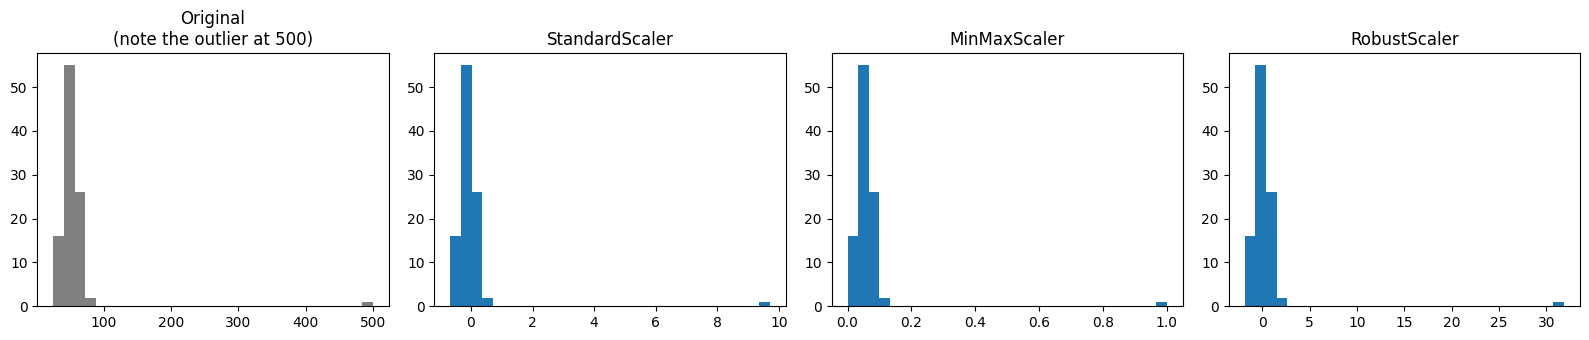

In [9]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, Normalizer

np.random.seed(0)
# Deliberately include an extreme outlier to demonstrate RobustScaler's advantage
demo_feature = np.concatenate([np.random.normal(50, 10, 99), [500]]).reshape(-1, 1)

scalers = {
    "StandardScaler": StandardScaler(),
    "MinMaxScaler": MinMaxScaler(),
    "RobustScaler": RobustScaler(),
}

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
axes[0].hist(demo_feature, bins=30, color="gray")
axes[0].set_title("Original\n(note the outlier at 500)")

for ax, (name, scaler) in zip(axes[1:], scalers.items()):
    transformed = scaler.fit_transform(demo_feature)
    ax.hist(transformed, bins=30, color="tab:blue")
    ax.set_title(name)

plt.tight_layout()
plt.show()


### The Mathematics, Parameters, and When to Use Each

**`StandardScaler`** — `z = (x - mean) / std`. Output has mean 0, std 1 (not bounded to a fixed range). **Sensitive to outliers** (a single extreme value inflates `std`, compressing the rest of the distribution) — visible above as the bulk of the "normal" data getting squeezed near zero. The default choice for linear models, SVM, PCA, neural networks.
- Key fitted attributes: `.mean_`, `.scale_` (the std actually used).
- Key parameter: `with_mean`, `with_std` (both default `True`; set `with_mean=False` for sparse data, since centering would destroy sparsity — Chapter 62).

**`MinMaxScaler`** — `x_scaled = (x - min) / (max - min)`. Output bounded exactly to `[0, 1]` (or a custom `feature_range`). **Extremely sensitive to outliers** — a single extreme value stretches the "normal" range into a tiny sliver near 0, exactly as shown above. Good when you need a strictly bounded range (e.g., for some neural network activation assumptions) and you're confident there are no extreme outliers.
- Key fitted attributes: `.data_min_`, `.data_max_`.
- Key parameter: `feature_range=(0, 1)` (customizable).

**`RobustScaler`** — `x_scaled = (x - median) / IQR`. Uses median and interquartile range instead of mean/std — **robust to outliers by construction**, visible above as the "normal" bulk of data staying well-spread even with the extreme outlier present. The correct default whenever outliers are known or suspected to exist and you don't want them distorting every other feature's scale.
- Key fitted attributes: `.center_` (the median), `.scale_` (the IQR).

**`Normalizer`** — fundamentally different from the other three: it scales each **row** (sample) to have unit norm, not each column (feature). Used for text/TF-IDF data and specific distance-based contexts (e.g., cosine similarity), rarely for standard tabular feature scaling — a common interview trap, since its name suggests it's just "another StandardScaler-like option" when it actually operates on an entirely different axis.

### Comparison Table
| Scaler | Formula | Output range | Outlier sensitivity | Typical use |
|---|---|---|---|---|
| `StandardScaler` | `(x-mean)/std` | Unbounded, mean 0 | High | Default for linear models, SVM, PCA |
| `MinMaxScaler` | `(x-min)/(max-min)` | Exactly `[0,1]` | Very high | Neural nets needing bounded input, no outliers present |
| `RobustScaler` | `(x-median)/IQR` | Unbounded | Low (by design) | Data with known outliers |
| `Normalizer` | per-row unit norm | Unit vector per row | N/A (different axis entirely) | Text/TF-IDF, cosine-similarity contexts |


In [10]:
# Demonstrating the critical rule: fit ONLY on training data, transform train AND test with those same params
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_s)     # LEARNS mean/std from training data, then applies it
X_test_scaled = scaler.transform(X_test_s)            # APPLIES the SAME learned mean/std -- no relearning

print("Scaler learned mean (first 3 features):", scaler.mean_[:3].round(2))
print("Training data transformed mean (~0):   ", X_train_scaled[:, :3].mean(axis=0).round(4))
print("Test data transformed mean (NOT ~0!):  ", X_test_scaled[:, :3].mean(axis=0).round(4))
print("\n(Test isn't exactly mean-0 -- that's EXPECTED and CORRECT: it proves we used")
print(" training statistics, not test statistics, to transform the test set.)")


Scaler learned mean (first 3 features): [14.07 19.25 91.56]
Training data transformed mean (~0):    [-0.  0. -0.]
Test data transformed mean (NOT ~0!):   [0.0858 0.048  0.0852]

(Test isn't exactly mean-0 -- that's EXPECTED and CORRECT: it proves we used
 training statistics, not test statistics, to transform the test set.)


### Effect on Models — A Concrete Demonstration


In [11]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# WITHOUT scaling
knn_unscaled = KNeighborsClassifier().fit(X_train_s, y_train_s)
acc_unscaled = accuracy_score(y_test_s, knn_unscaled.predict(X_test_s))

# WITH scaling
knn_scaled = KNeighborsClassifier().fit(X_train_scaled, y_train_s)
acc_scaled = accuracy_score(y_test_s, knn_scaled.predict(X_test_scaled))

print(f"KNN accuracy WITHOUT scaling: {acc_unscaled:.4f}")
print(f"KNN accuracy WITH scaling:    {acc_scaled:.4f}")
print("\nKNN is distance-based -- unscaled features with large numeric ranges dominate distance")
print("calculations regardless of true predictive value, which is exactly what scaling fixes.")


KNN accuracy WITHOUT scaling: 0.9123
KNN accuracy WITH scaling:    0.9561

KNN is distance-based -- unscaled features with large numeric ranges dominate distance
calculations regardless of true predictive value, which is exactly what scaling fixes.


### Common Mistakes
- Calling `scaler.fit_transform()` on the **entire** dataset before splitting into train/test — this is the single most common data leakage pattern in beginner Scikit-learn code (explicitly flagged as an anti-pattern in this course's source curriculum). It leaks test-set mean/std into the scaling parameters used for training, subtly inflating apparent test performance.
- Scaling before splitting instead of after: `scaler.fit_transform(X); X_train, X_test = train_test_split(X)` — the exact same leakage, just written in a different order.
- Applying `MinMaxScaler` to data with known extreme outliers, then being confused why the bulk of "normal" values end up compressed near 0.
- Scaling a tree-based model's input "just in case" — harmless but unnecessary; understanding *why* it's unnecessary (Section 2's table) is the more valuable interview-relevant knowledge than blindly always scaling.

### Best Practices
- Always fit scalers on training data only; use `.transform()` (never `.fit_transform()`) on validation/test data.
- Default to `RobustScaler` when outliers are known/suspected; `StandardScaler` otherwise, for any distance/gradient-sensitive model.
- Skip scaling entirely for pure tree-based models (though it causes no harm, it's wasted computation and can be a subtle interview trap to over-apply reflexively).

### Interview Insight
**Q: `scaler.fit_transform(X)` is called on the full dataset, before `train_test_split()`. What's wrong, and what's the correct order?**
A: This leaks test-set statistics (mean, std, min, max, or median/IQR depending on the scaler) into the parameters used to transform the training data, since the scaler's `.fit()` sees the entire dataset including what will become the test set. The correct order is to split first, then `scaler.fit_transform(X_train)` (learn parameters from training data only), then `scaler.transform(X_test)` (apply those same training-derived parameters to the test set, without relearning).

**Q: Why doesn't Random Forest need feature scaling, but KNN does?**
A: Random Forest (like any tree-based model) splits each feature independently against a threshold — the *absolute scale* of a feature doesn't affect which threshold best separates the target, only the feature's relative ordering, which scaling doesn't change. KNN and other distance-based/gradient-based methods directly compute magnitudes (Euclidean distance, gradient steps) across all features jointly, so a feature with a naturally larger numeric range will dominate that computation unless every feature is first brought onto a comparable scale.

### Mini Exercise
Repeat the KNN scaling comparison using `LogisticRegression` instead, and observe whether the scaling effect is as dramatic — logistic regression is also scale-sensitive (via its regularization term and gradient-based solver), but the size of the effect can differ from KNN's purely distance-based sensitivity.

### Quiz (Chapter 5)
1. Which two categories of models are scale-sensitive, and which are not, and why?
2. Why is `RobustScaler` preferred over `StandardScaler`/`MinMaxScaler` when outliers are present?
3. What makes `Normalizer` fundamentally different from the other three scalers?
4. Walk through exactly why fitting a scaler before `train_test_split()` causes data leakage.

### Chapter 5 Summary
- Scaling puts numerical features on a comparable footing for distance/gradient-based algorithms; tree-based models don't need it.
- `StandardScaler` (default), `MinMaxScaler` (bounded range, outlier-sensitive), `RobustScaler` (outlier-robust), `Normalizer` (per-row, different axis entirely — mainly text/TF-IDF).
- The leakage rule established here — fit only on train, transform train and test with those same parameters — is the seed of everything Chapters 10–11 (ColumnTransformer, Pipeline) exist to enforce automatically and safely.

---

## END OF NOTEBOOK 1 — What You Should Now Be Able To Do
- Explain where Scikit-learn sits in the Python ML ecosystem and what it deliberately does not provide.
- Correctly distinguish Estimator / Transformer / Predictor / Meta-estimator roles and their method contracts.
- Diagnose and fix the single most common shape error (`Expected 2D array, got 1D array`).
- Build a correct, reproducible, stratified train/validation/test split and explain why the test set must be touched only once.
- Choose the correct scaler for a given situation and explain precisely why tree-based models don't need scaling while distance/gradient-based models do.
- Recognize and avoid the "scale before split" data leakage anti-pattern — the foundational leakage lesson this entire course will keep building on.

## Before Moving to Notebook 2 (Chapters 6–10: Categorical Encoding, Missing Value Imputation, Feature Generation, Custom Transformers, ColumnTransformer)

